In [2]:
import numpy as np
import scipy.io as scio
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
data, data_X, data_y = [],[],[]
file_path = "D:\\1 ارشد\پایان نامه\\گزارش 23 - ارائه پروپوزال\\TE Data\\"

for mode in ['1','2','3','4','5','6']:
    mode_name = 'm' + mode + 'd00'
    temp = scio.loadmat(file_path + mode_name)[mode_name]
    #data.append(temp.copy())
    data_X.append(temp[:,[0, 1, 2, 3, 4, 5, 8, 9, 10, 12, 13, 15, 17, 18, 20, 21]].copy())
    data_y.append(temp[:,32].copy())  #purge E

np.round(pd.DataFrame(data_X[1]),3).head()


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,0.307,737.367,8033.449,8.561,31.701,46.110,124.205,0.354,90.306,2705.738,26.315,3328.012,65.418,4.898,108.524,91.509
1,0.306,731.896,8083.074,8.655,31.630,46.230,124.201,0.354,90.252,2705.751,26.224,3328.070,65.433,5.247,108.513,91.354
2,0.309,725.945,8033.404,8.579,31.647,46.043,124.195,0.353,90.237,2704.870,26.214,3327.154,65.427,4.299,108.524,91.433
3,0.309,751.991,8011.162,8.496,31.965,46.419,124.191,0.353,90.220,2705.372,26.371,3327.004,65.424,4.100,108.541,91.600
4,0.305,723.574,8042.783,8.588,31.571,46.129,124.201,0.354,90.245,2705.674,26.466,3327.606,65.413,5.565,108.532,91.634


In [112]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

data_X_scaled = []
scaler_0 = StandardScaler()
scaler_0.fit(data_X[0][:,:])
for mode in range(6):
    data_X_scaled.append(scaler_0.transform(data_X[mode][:,:]))


In [82]:
from importlib import reload
import my_BLS_Regression_5
reload(my_BLS_Regression_5)
from my_BLS_Regression_5 import BLS_regression
from my_BLS_Regression_5 import standard_scaler

In [4]:
from sklearn.model_selection import train_test_split

In [5]:
X_trainvalid, X_test, y_trainvalid, y_test = train_test_split(data_X[0], data_y[0], test_size=.25, random_state = 77)
X_train, X_valid, y_train, y_valid = train_test_split(X_trainvalid, y_trainvalid, test_size=.14, random_state = 77)
X_train.shape, X_valid.shape, X_test.shape

((4643, 16), (757, 16), (1801, 16))

In [45]:
result_relu6 = []
model_relu6 = BLS_regression(0.001, 1, 10, 8, 6, 3, activation='relu6')

model_relu6.fit(X_train, y_train)
result_relu6 += [model_relu6.fit_RMSE, round(model_relu6.fit_MAPE*100, 3)]

model_relu6.predict(X_valid, y_valid)
result_relu6 += [model_relu6.pred_RMSE, round(model_relu6.pred_MAPE*100, 3)]

model_relu6.predict(X_test, y_test)
result_relu6 += [model_relu6.pred_RMSE, round(model_relu6.pred_MAPE*100, 3)]


In [47]:
result_sigmoid = []
model_sigmoid = BLS_regression(0.001, 1, 10, 8, 6, 3, activation='sigmoid')

model_sigmoid.fit(X_train, y_train)
result_sigmoid += [model_sigmoid.fit_RMSE, round(model_sigmoid.fit_MAPE*100, 3)]

model_sigmoid.predict(X_valid, y_valid)
result_sigmoid += [model_sigmoid.pred_RMSE, round(model_sigmoid.pred_MAPE*100, 3)]

model_sigmoid.predict(X_test, y_test)
result_sigmoid += [model_sigmoid.pred_RMSE, round(model_sigmoid.pred_MAPE*100, 3)]


In [49]:
print(result_relu6, '\n', result_sigmoid)

[0.24565400293006975, 1.229, 0.24028874683484014, 1.199, 0.25442562875227775, 1.278] 
 [0.2453947244585013, 1.228, 0.2402774267949451, 1.201, 0.25404464676664895, 1.275]


[0.24565400293006975, 1.229, 0.24028874683484014, 1.199, 0.25442562875227775, 1.278] 
 [0.2453947244585013, 1.228, 0.2402774267949451, 1.201, 0.25404464676664895, 1.275]

In [53]:
[round(result_relu6[i] - result_sigmoid[i], 5) for i in range(len(result_sigmoid))]

[0.00026, 0.001, 1e-05, -0.002, 0.00038, 0.003]

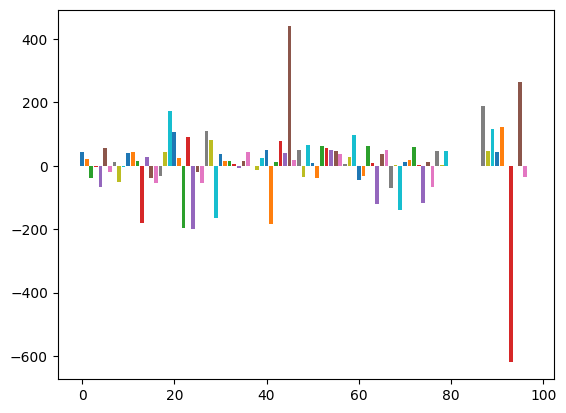

In [58]:
[plt.bar(i , height=model_relu6.Wn[i]) for i in range(len(model_relu6.Wn))];

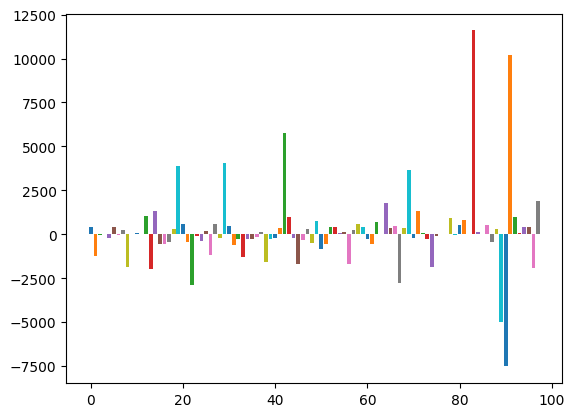

In [59]:
[plt.bar(i , height=model_sigmoid.Wn[i]) for i in range(len(model_sigmoid.Wn))];

In [80]:
model_relu6.Wn, model_sigmoid.Wn

(array([  44.44675822,   20.21943287,  -38.26399527,   -2.18893623,
         -65.97545145,   57.12931942,  -18.81874738,   11.21997799,
         -50.72386753,   -2.18893623,   41.09018092,   42.29807698,
          14.75594165, -180.58881842,   26.50247   ,  -38.678527  ,
         -53.17256217,  -31.27433687,   43.72403995,  172.54591107,
         105.99530201,   24.60097313, -195.20322363,   92.02710777,
        -199.71350479,  -18.70774494,  -52.82166919,  108.42278415,
          80.19420568, -165.63195633,   35.73762632,   13.86800243,
          16.21104674,    7.23780386,   -6.1058179 ,   15.77034724,
          42.82914169,   -1.07355888,  -14.01470494,   25.37863235,
          50.95538507, -182.42854633,   13.48915209,   77.3391811 ,
          41.17325745,  439.43560079,   18.11379401,   51.15622962,
         -35.89874806,   64.46872069,    7.70944569,  -39.78340282,
          62.32525026,   56.11839763,   50.28715398,   46.75973158,
          37.95275766,    4.49815913,   26.99014

In [63]:
max(model_sigmoid.Wn), min(model_sigmoid.Wn)

(11598.109985709965, -7524.9111561174195)

In [64]:
max(model_relu6.Wn), min(model_relu6.Wn)

(439.43560079249164, -620.1517035347991)

<Axes: ylabel='Density'>

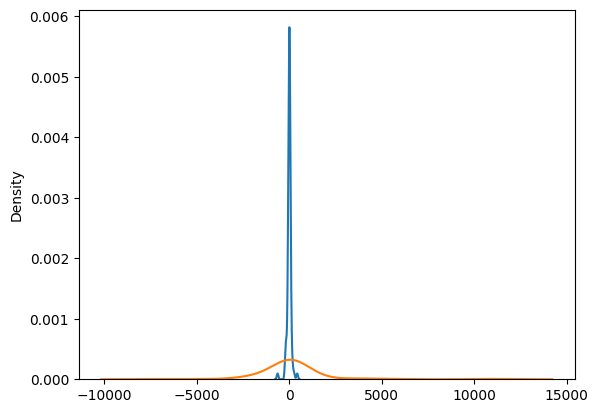

In [69]:
sns.kdeplot(model_relu6.Wn)
sns.kdeplot(model_sigmoid.Wn)

In [83]:
result_scaler_relu6 = []
model_scaler_relu6 = BLS_regression(0.001, 1, 10, 8, 6, 3, activation='relu6')

model_scaler_relu6.fit(X_train, y_train)
result_scaler_relu6 += [model_scaler_relu6.fit_RMSE, round(model_scaler_relu6.fit_MAPE*100, 3)]

model_scaler_relu6.predict(X_valid, y_valid)
result_scaler_relu6 += [model_scaler_relu6.pred_RMSE, round(model_scaler_relu6.pred_MAPE*100, 3)]

model_scaler_relu6.predict(X_test, y_test)
result_scaler_relu6 += [model_scaler_relu6.pred_RMSE, round(model_scaler_relu6.pred_MAPE*100, 3)]


In [84]:
result_scaler_relu6

[0.24443822781319174,
 1.218,
 0.24254825764002244,
 1.208,
 0.25440055544920914,
 1.274]

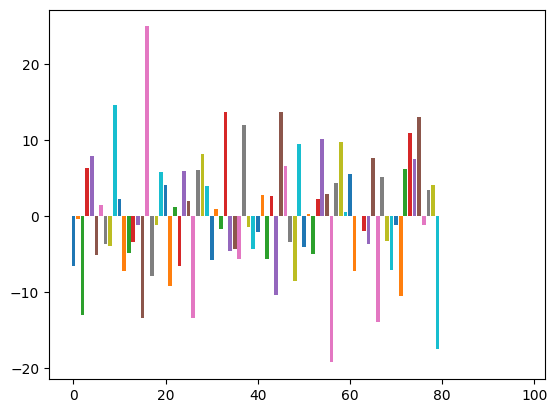

In [76]:
[plt.bar(i , height=model_scaler_relu6.Wn[i]) for i in range(len(model_scaler_relu6.Wn))];

In [77]:
model_scaler_relu6.Wn[90]

-0.005126943384877289

<Axes: ylabel='Density'>

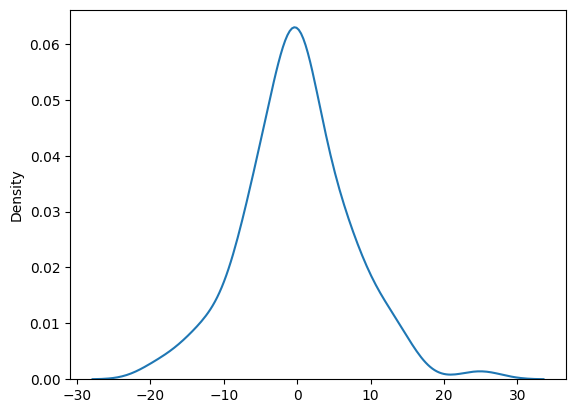

In [75]:
sns.kdeplot(model_scaler_relu6.Wn)

In [78]:
max(model_scaler_relu6.Wn), min(model_scaler_relu6.Wn)

(24.950276345786413, -19.24856778059278)

In [79]:
model_scaler_relu6.Wn

array([-6.57938303e+00, -3.80175637e-01, -1.29375532e+01,  6.34242493e+00,
        7.86136508e+00, -5.12731939e+00,  1.50449424e+00, -3.64533435e+00,
       -3.90449357e+00,  1.46863715e+01,  2.26655855e+00, -7.27141748e+00,
       -4.83459805e+00, -3.45326008e+00, -1.17012851e+00, -1.34350717e+01,
        2.49502763e+01, -7.84770406e+00, -1.19496692e+00,  5.82884357e+00,
        4.16041660e+00, -9.18842026e+00,  1.24918264e+00, -6.53787920e+00,
        5.87918927e+00,  1.96488324e+00, -1.34505989e+01,  6.00843414e+00,
        8.17098608e+00,  4.01115307e+00, -5.76856736e+00,  8.94937411e-01,
       -1.73917794e+00,  1.37421496e+01, -4.52957863e+00, -4.32089112e+00,
       -5.59379107e+00,  1.20404631e+01, -1.39893471e+00, -4.28007578e+00,
       -2.05365801e+00,  2.73383972e+00, -5.67325520e+00,  2.65101632e+00,
       -1.03932009e+01,  1.36385044e+01,  6.65680470e+00, -3.33985169e+00,
       -8.48116498e+00,  9.47911293e+00, -4.08393542e+00,  2.32288419e-01,
       -5.01752183e+00,  

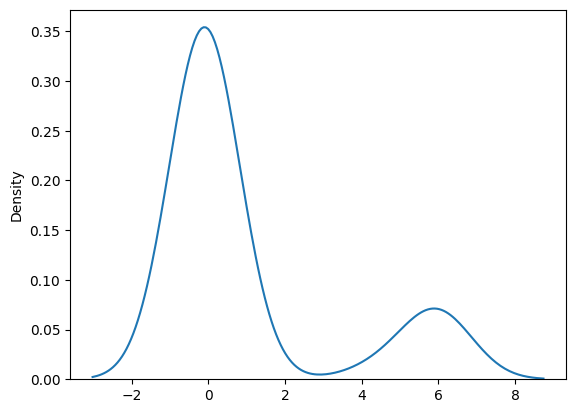

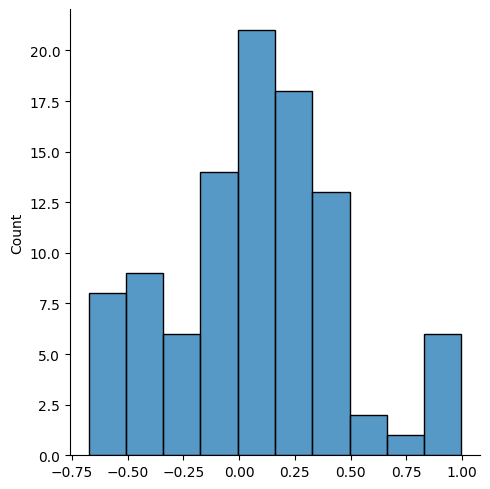

In [102]:
sns.kdeplot(model_scaler_relu6.An[0])
sns.displot(model_sigmoid.An[0])

In [92]:
max(model_scaler_relu6.An[330]), min(model_scaler_relu6.An[330])

(6.0, -0.3292659744791449)

In [117]:
min(model_scaler_relu6.An[0][:80]), max(model_scaler_relu6.An[0][:80]), min(model_scaler_relu6.An[0][80:]), max(model_scaler_relu6.An[0][80:])

(-0.2731666637086499, 0.13667592167811846, 4.210321880981428, 6.0)

In [105]:
result_scaler_sigmoid = []
model_scaler_sigmoid = BLS_regression(0.001, 1, 10, 8, 6, 3, activation='sigmoid')

model_scaler_sigmoid.fit(X_train, y_train)
result_scaler_sigmoid += [model_scaler_sigmoid.fit_RMSE, round(model_scaler_sigmoid.fit_MAPE*100, 3)]

model_scaler_sigmoid.predict(X_valid, y_valid)
result_scaler_sigmoid += [model_scaler_sigmoid.pred_RMSE, round(model_scaler_sigmoid.pred_MAPE*100, 3)]

model_scaler_sigmoid.predict(X_test, y_test)
result_scaler_sigmoid += [model_scaler_sigmoid.pred_RMSE, round(model_scaler_sigmoid.pred_MAPE*100, 3)]


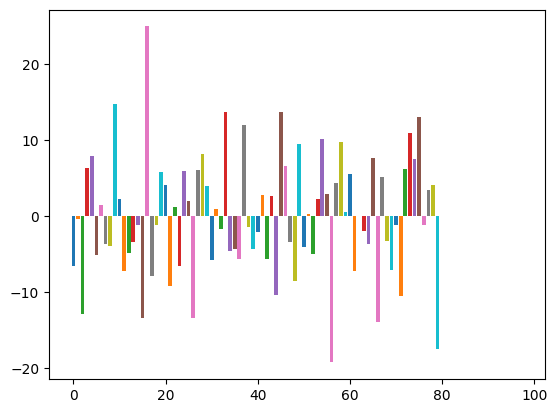

In [107]:
[plt.bar(i , height=model_scaler_sigmoid.Wn[i]) for i in range(len(model_scaler_sigmoid.Wn))];

array([-6.57802378e+00, -3.74265685e-01, -1.29053503e+01,  6.33389960e+00,
        7.86090292e+00, -5.09839928e+00,  1.50019135e+00, -3.62404096e+00,
       -3.88958577e+00,  1.46644180e+01,  2.27027912e+00, -7.24551597e+00,
       -4.82660294e+00, -3.45457291e+00, -1.15759256e+00, -1.34050204e+01,
        2.49121429e+01, -7.84086942e+00, -1.19281854e+00,  5.82778093e+00,
        4.15188744e+00, -9.18283761e+00,  1.26021564e+00, -6.52048426e+00,
        5.86956615e+00,  1.96216751e+00, -1.34280604e+01,  6.01019269e+00,
        8.15887710e+00,  4.01342259e+00, -5.75863624e+00,  8.90687751e-01,
       -1.72340929e+00,  1.37281972e+01, -4.52141414e+00, -4.30059028e+00,
       -5.57319338e+00,  1.20272249e+01, -1.39248620e+00, -4.27188185e+00,
       -2.04641116e+00,  2.72320671e+00, -5.66269680e+00,  2.64229396e+00,
       -1.03688511e+01,  1.36240221e+01,  6.64736899e+00, -3.33781249e+00,
       -8.46673589e+00,  9.46843091e+00, -4.07393977e+00,  2.36160291e-01,
       -5.00304868e+00,  

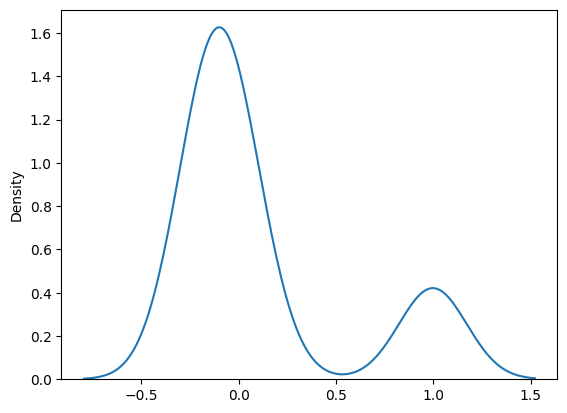

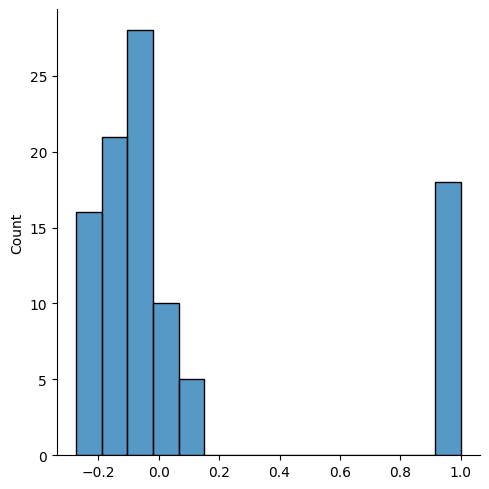

In [110]:
sns.kdeplot(model_scaler_sigmoid.An[0])
sns.displot(model_scaler_sigmoid.An[0])
model_scaler_sigmoid.An[0]
model_scaler_sigmoid.Wn

In [113]:
model_scaler_relu6.clip_min, model_scaler_relu6.clip_max

(array([-2.56203858, -2.65313229, -2.53042198, -2.58677029, -2.51326986,
        -2.5955356 , -2.53018303, -2.6318687 , -2.53586756, -2.74122518,
        -2.57659085, -2.83670109, -2.71101794, -2.56426055, -2.43549701,
        -2.54660154]),
 array([2.29470507, 2.5538017 , 2.63026028, 2.53148862, 2.4783891 ,
        2.54496222, 2.49453686, 2.71936823, 2.56782626, 2.53146674,
        2.48596239, 2.56073696, 2.53347992, 2.5656508 , 2.5367208 ,
        2.58443312]))

## condition monitoring

In [145]:
from importlib import reload
import my_BLS_Regression_6_Condition_number
reload(my_BLS_Regression_6_Condition_number)
from my_BLS_Regression_6_Condition_number import BLS_regression as BLS_reg_6

In [146]:
result_cond = []
model_cond = [0, 0, 0]
for index, i in enumerate(['all', 'none', 'scale']):
    model_cond[index] = BLS_reg_6(0.001, 1, 10, 8, 6, 3, activation='relu6', condition=i)
    model_cond[index].fit(X_train, y_train)


# model_cond.fit(X_train, y_train)
# result_cond += [model_cond.fit_RMSE, round(model_cond.fit_MAPE*100, 3)]

# model_cond.predict(X_valid, y_valid)
# result_cond += [model_cond.pred_RMSE, round(model_cond.pred_MAPE*100, 3)]

# model_cond.predict(X_test, y_test)
# result_cond += [model_cond.pred_RMSE, round(model_cond.pred_MAPE*100, 3)]


The condition number in all is:	3.6252092566343333e+21 and	663302656.4594443
The condition number in none is:	inf and	599400716.1718577
The condition number in scale is:	5.782586956991768e+21 and	649002594.3464736


In [150]:
for index, i in enumerate([1, 0.1, 0.01, 0.001, 0.0001, 0.00001, 0]):
    model_cond_lambda = BLS_reg_6(i, 1, 10, 8, 6, 3, activation='relu6')
    model_cond_lambda.fit(X_train, y_train)

The condition number in all is:	3.6252092566343333e+21 and	663303.6546160845
The condition number in all is:	3.6252092566343333e+21 and	6633027.546278798
The condition number in all is:	3.6252092566343333e+21 and	66330266.47117847
The condition number in all is:	3.6252092566343333e+21 and	663302656.4594443
The condition number in all is:	3.6252092566343333e+21 and	6633026662.733323
The condition number in all is:	3.6252092566343333e+21 and	66330271314.36716
The condition number in all is:	3.6252092566343333e+21 and	3.6252092566343333e+21


In [156]:
eig = np.linalg.eigvalsh(model_cond[0].An.T @ model_cond[0].An)
print(eig[-1], eig[0])   # max, min

663302.6546154275 -1.1716836207578395e-10


In [147]:
result_cond = []
model_cond_sig = [0, 0, 0]
for index, i in enumerate(['all', 'none', 'scale']):
    model_cond_sig[index] = BLS_reg_6(0.001, 1, 10, 8, 6, 3, activation='sigmoid', condition=i)
    model_cond_sig[index].fit(X_train, y_train)

The condition number in all is:	3.5473911315792732e+19 and	34586208.40454699
The condition number in none is:	9.005159957514542e+23 and	69485271.21581839
The condition number in scale is:	1.3581059553119491e+20 and	34415066.00277615


## QAT and PTQ -- Asymmetric

In [6]:
from importlib import reload
import my_BLS_Regression_7_QAT
reload(my_BLS_Regression_7_QAT)
from my_BLS_Regression_7_QAT import BLS_regression as BLS_reg_7

In [201]:
# --- 1. BASELINE (FLOAT) ---
model_baseline = BLS_reg_7(0.1, 1, 10, 8, 6, 3)
model_baseline.fit(X_train, y_train) # Uses the modified 'fit' that skips QAT
model_baseline.predict(X_test, y_test)
rmse_baseline = model_baseline.pred_RMSE
mape_baseline = model_baseline.pred_MAPE

# --- 2. QAT (NEW MODEL) ---
model_qat = BLS_reg_7(0.1, 1, 10, 8, 6, 3)
model_qat.fit(X_train, y_train, QAT=True) # Uses the full 'fit' with QAT
model_qat.predict(X_test, y_test)
rmse_qat = model_qat.pred_RMSE
mape_qat = model_qat.pred_MAPE

# --- 3. PTQ (NEW PREDICT FUNCTION) ---
# Use the model from Step 1 (model_baseline)
model_baseline.predict(X_test, y_test, PTQ=True)
rmse_ptq = model_baseline.pred_RMSE
mape_ptq = model_baseline.pred_MAPE

model_qat.predict(X_test, y_test, PTQ = True, QAT=True)
rmse_qat_ptq = model_qat.pred_RMSE
mape_qat_ptq = model_qat.pred_MAPE

# --- 4. FINAL COMPARISON ---
print(f"Baseline (Float) Test RMSE: {rmse_baseline}\t{mape_baseline*100:.4f}")
print(f"PTQ Test RMSE:              {rmse_ptq}\t{mape_ptq*100:.4f}")
print(f"QAT Test RMSE:              {rmse_qat}\t{mape_qat*100:.4f}")
print(f"QAT_PTQ Test RMSE:          {rmse_qat_ptq}\t{mape_qat_ptq*100:.4f}")

Baseline (Float) Test RMSE: 0.25474071948502003	1.2768
PTQ Test RMSE:              0.28468588743376066	1.4141
QAT Test RMSE:              0.2547800900991502	1.2762
QAT_PTQ Test RMSE:          0.2673575429881197	1.3451


Baseline (Float) Test RMSE: 0.25474071948502003	1.2768
PTQ Test RMSE:              0.28468588743376066	1.4141
QAT Test RMSE:              0.2547800900991502	1.2762
QAT_PTQ Test RMSE:          0.2673575429881197	1.3451

## QAT and PTQ -- Symmetric

In [8]:
from importlib import reload
import my_BLS_Regression_7_QAT_universal
reload(my_BLS_Regression_7_QAT_universal)
from my_BLS_Regression_7_QAT_universal import BLS_regression as BLS_reg_8

In [208]:
# --- 1. BASELINE (FLOAT) ---
model_baseline = BLS_reg_8(0.1, 1, 10, 8, 6, 3)
model_baseline.fit(X_train, y_train) # Uses the modified 'fit' that skips QAT
model_baseline.predict(X_test, y_test)
rmse_baseline = model_baseline.pred_RMSE
mape_baseline = model_baseline.pred_MAPE

# --- 2. QAT (NEW MODEL) ---
model_qat = BLS_reg_8(0.1, 1, 10, 8, 6, 3)
model_qat.fit(X_train, y_train, QAT=True) # Uses the full 'fit' with QAT
model_qat.predict(X_test, y_test)
rmse_qat = model_qat.pred_RMSE
mape_qat = model_qat.pred_MAPE

# --- 3. PTQ (NEW PREDICT FUNCTION) ---
# Use the model from Step 1 (model_baseline)
model_baseline.predict(X_test, y_test, PTQ=True)
rmse_ptq = model_baseline.pred_RMSE
mape_ptq = model_baseline.pred_MAPE

model_qat.predict(X_test, y_test, PTQ = True, QAT=True)
rmse_qat_ptq = model_qat.pred_RMSE
mape_qat_ptq = model_qat.pred_MAPE

# --- 4. FINAL COMPARISON ---
print(f"Baseline (Float) Test RMSE: {rmse_baseline}\t{mape_baseline*100:.4f}")
print(f"PTQ Test RMSE:              {rmse_ptq}\t{mape_ptq*100:.4f}")
print(f"QAT Test RMSE:              {rmse_qat}\t{mape_qat*100:.4f}")
print(f"QAT_PTQ Test RMSE:          {rmse_qat_ptq}\t{mape_qat_ptq*100:.4f}")

Baseline (Float) Test RMSE: 0.25474071948502003	1.2768
PTQ Test RMSE:              0.2892451960747709	1.4383
QAT Test RMSE:              0.254835014804235	1.2789
QAT_PTQ Test RMSE:          0.2902854511380393	1.4495


Baseline (Float) Test RMSE: 0.25474071948502003	1.2768
PTQ Test RMSE:              0.2892451960747709	1.4383
QAT Test RMSE:              0.254835014804235	1.2789
QAT_PTQ Test RMSE:          0.2902854511380393	1.4495

## QAT and PTQ -- Mixed Quantization

In [210]:
# --- 1. BASELINE (FLOAT) ---
model_baseline = BLS_reg_8(0.1, 1, 10, 8, 6, 3)
model_baseline.fit(X_train, y_train) # Uses the modified 'fit' that skips QAT
model_baseline.predict(X_test, y_test)
rmse_baseline = model_baseline.pred_RMSE
mape_baseline = model_baseline.pred_MAPE

# --- 2. QAT (NEW MODEL) ---
model_qat = BLS_reg_8(0.1, 1, 10, 8, 6, 3)
model_qat.fit(X_train, y_train, QAT=True) # Uses the full 'fit' with QAT
model_qat.predict(X_test, y_test)
rmse_qat = model_qat.pred_RMSE
mape_qat = model_qat.pred_MAPE

# --- 3. PTQ (NEW PREDICT FUNCTION) ---
# Use the model from Step 1 (model_baseline)
model_baseline.predict(X_test, y_test, PTQ=True)
rmse_ptq = model_baseline.pred_RMSE
mape_ptq = model_baseline.pred_MAPE

model_qat.predict(X_test, y_test, PTQ = True, QAT=True)
rmse_qat_ptq = model_qat.pred_RMSE
mape_qat_ptq = model_qat.pred_MAPE

# --- 4. FINAL COMPARISON ---
print(f"Baseline (Float) Test RMSE: {rmse_baseline}\t{mape_baseline*100:.4f}")
print(f"PTQ Test RMSE:              {rmse_ptq}\t{mape_ptq*100:.4f}")
print(f"QAT Test RMSE:              {rmse_qat}\t{mape_qat*100:.4f}")
print(f"QAT_PTQ Test RMSE:          {rmse_qat_ptq}\t{mape_qat_ptq*100:.4f}")

Baseline (Float) Test RMSE: 0.25474071948502003	1.2768
PTQ Test RMSE:              0.2883278954004187	1.4260
QAT Test RMSE:              0.2547800900991502	1.2762
QAT_PTQ Test RMSE:          0.2713669007853251	1.3602


Baseline (Float) Test RMSE: 0.25474071948502003	1.2768
PTQ Test RMSE:              0.2883278954004187	1.4260
QAT Test RMSE:              0.2547800900991502	1.2762
QAT_PTQ Test RMSE:          0.2713669007853251	1.3602

## QAT and PTQ -- ASymmetric again

In [9]:
# --- 1. BASELINE (FLOAT) ---
model_baseline = BLS_reg_8(0.1, 1, 10, 8, 6, 3)
model_baseline.fit(X_train, y_train) # Uses the modified 'fit' that skips QAT
model_baseline.predict(X_test, y_test)
rmse_baseline = model_baseline.pred_RMSE
mape_baseline = model_baseline.pred_MAPE

# --- 2. QAT (NEW MODEL) ---
model_qat = BLS_reg_8(0.1, 1, 10, 8, 6, 3)
model_qat.fit(X_train, y_train, QAT=True) # Uses the full 'fit' with QAT
model_qat.predict(X_test, y_test)
rmse_qat = model_qat.pred_RMSE
mape_qat = model_qat.pred_MAPE

# --- 3. PTQ (NEW PREDICT FUNCTION) ---
# Use the model from Step 1 (model_baseline)
model_baseline.predict(X_test, y_test, PTQ=True)
rmse_ptq = model_baseline.pred_RMSE
mape_ptq = model_baseline.pred_MAPE

model_qat.predict(X_test, y_test, PTQ = True, QAT=True)
rmse_qat_ptq = model_qat.pred_RMSE
mape_qat_ptq = model_qat.pred_MAPE

# --- 4. FINAL COMPARISON ---
print(f"Baseline (Float) Test RMSE: {rmse_baseline}\t{mape_baseline*100:.4f}")
print(f"PTQ Test RMSE:              {rmse_ptq}\t{mape_ptq*100:.4f}")
print(f"QAT Test RMSE:              {rmse_qat}\t{mape_qat*100:.4f}")
print(f"QAT_PTQ Test RMSE:          {rmse_qat_ptq}\t{mape_qat_ptq*100:.4f}")

Baseline (Float) Test RMSE: 0.25474071948502003	1.2768
PTQ Test RMSE:              0.28468588743376066	1.4141
QAT Test RMSE:              0.2547800900991502	1.2762
QAT_PTQ Test RMSE:          0.2673575429881197	1.3451


In [16]:
import matplotlib as mpl
from matplotlib.font_manager import FontProperties
import plotfa
from plotfa import fa

In [17]:

# Step 1: Configure plotfa and Matplotlib
plotfa.set_font('B Nazanin') # Sets a default Persian font.
plotfa.prettify()

plt.rcParams['axes.unicode_minus'] = False


In [ ]:
fig, ax = plt.subplots(figsize = (6,4))
ax.plot(range(30), buffer_1, color = 'b', label=fa('نمونه‌ی یکم، از حالت یکم'))
ax.plot(range(30,60), buffer_3, color = 'red', label=fa('نمونه‌ی دوم، از حالت یکم'))
ax.axvline(30, color='black', alpha = 0.5, linestyle='--')
ax.set_xlabel(fa('زمان'), fontsize=13)
ax.set_ylabel(fa('دمای جداکننده $(C°)$') + '', fontsize=13)
# ax.text(x=-0.15, y=0.5, s='(°C)', fontproperties=latin_font, transform=ax.transAxes, ha='center', va='center')

ax.set_title(fa('دو نمونه‌ی انتخابی از فرآیند $TE$ '), fontsize=14)
plt.legend();

C:\Users\Asus\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 108 (l) missing from font(s) B Nazanin.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Asus\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 112 (p) missing from font(s) B Nazanin.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Asus\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 67 (C) missing from font(s) B Nazanin.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Asus\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 111 (o) missing from font(s) B Nazanin.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Asus\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 117 (u) missing from font(s) B Nazanin.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Asus\AppData\Roaming\P

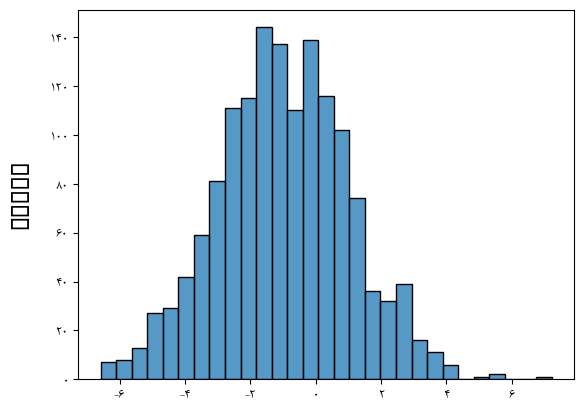

C:\Users\Asus\AppData\Local\Temp\ipykernel_5724\3523798361.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


C:\Users\Asus\AppData\Roaming\Python\Python311\site-packages\IPython\core\events.py:82: UserWarning: Glyph 108 (l) missing from font(s) B Nazanin.
  func(*args, **kwargs)
C:\Users\Asus\AppData\Roaming\Python\Python311\site-packages\IPython\core\events.py:82: UserWarning: Glyph 112 (p) missing from font(s) B Nazanin.
  func(*args, **kwargs)
C:\Users\Asus\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 108 (l) missing from font(s) B Nazanin.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Asus\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 112 (p) missing from font(s) B Nazanin.
  fig.canvas.print_figure(bytes_io, **kw)


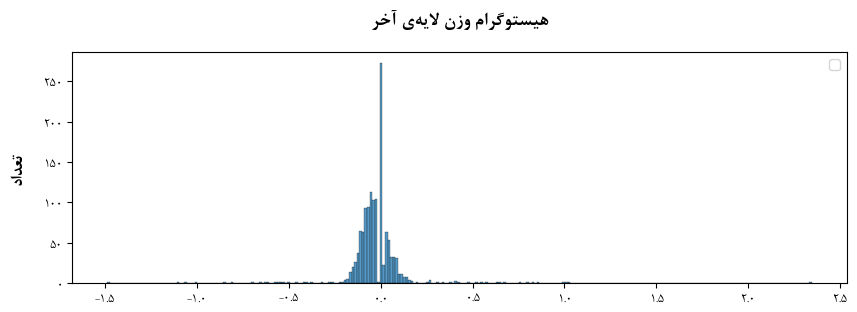

In [26]:

sns.histplot(np.array(model_baseline.Wh).flatten());
plt.show()
plt.figure(figsize=(10, 3))
sns.histplot(np.array(model_baseline.We).flatten());
plt.ylabel(fa("تعداد"), fontsize=13)
plt.title(fa("هیستوگرام وزن لایه‌ی آخر"), fontsize=14)
plt.legend()

## QAT and PTQ for all (+ We, Wn, X)

In [304]:
from importlib import reload
import my_BLS_Regression_7_QAT_all
reload(my_BLS_Regression_7_QAT_all)
from my_BLS_Regression_7_QAT_all import BLS_regression as BLS_reg_9

In [289]:
# --- 1. BASELINE (FLOAT) ---
model_baseline = BLS_reg_9(0.1, 1, 10, 8, 6, 3)
model_baseline.fit(X_train, y_train) # Uses the modified 'fit' that skips QAT
model_baseline.predict(X_test, y_test)
rmse_baseline = model_baseline.pred_RMSE
mape_baseline = model_baseline.pred_MAPE

# --- 2. QAT (NEW MODEL) ---
model_qat = BLS_reg_9(0.1, 1, 10, 8, 6, 3)
model_qat.fit(X_train, y_train, QAT=True) # Uses the full 'fit' with QAT
model_qat.predict(X_test, y_test)
rmse_qat = model_qat.pred_RMSE
mape_qat = model_qat.pred_MAPE

# --- 3. PTQ (NEW PREDICT FUNCTION) ---
# Use the model from Step 1 (model_baseline)
model_baseline.predict(X_test, y_test, PTQ=True)
rmse_ptq = model_baseline.pred_RMSE
mape_ptq = model_baseline.pred_MAPE

model_qat.predict(X_test, y_test, PTQ = True)
rmse_qat_ptq = model_qat.pred_RMSE
mape_qat_ptq = model_qat.pred_MAPE

# --- 4. FINAL COMPARISON ---
print(f"Baseline (Float) Test RMSE: {rmse_baseline}\t{mape_baseline*100:.4f}")
print(f"PTQ Test RMSE:              {rmse_ptq}\t{mape_ptq*100:.4f}")
print(f"QAT Test RMSE:              {rmse_qat}\t{mape_qat*100:.4f}")
print(f"QAT_PTQ Test RMSE:          {rmse_qat_ptq}\t{mape_qat_ptq*100:.4f}")

Baseline (Float) Test RMSE: 0.25474071948502003	1.2768
PTQ Test RMSE:              0.33997367026111014	1.6833
QAT Test RMSE:              0.3201784656013745	1.6020
QAT_PTQ Test RMSE:          0.28447991557988644	1.4167


Baseline (Float) Test RMSE: 0.25474071948502003	1.2768
PTQ Test RMSE:              0.33997367026111014	1.6833
QAT Test RMSE:              0.3201784656013745	1.6020
QAT_PTQ Test RMSE:          0.28447991557988644	1.4167

## ONNX

In [305]:
# --- 2. QAT (NEW MODEL) ---
model_qat_all = BLS_reg_9(0.1, 1, 10, 8, 6, 3)
model_qat_all.fit(X_train, y_train, QAT=True) # Uses the full 'fit' with QAT
# model_qat_all.predict(X_test, y_test)
# rmse_qat = model_qat_all.pred_RMSE
# mape_qat = model_qat_all.pred_MAPE

True

In [269]:
# NOTE: This code needs to be executed in your local environment.
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import tf2onnx 

# --- 1. Define Model Dimensions ---
N_FT_GROUPS = 10 
N_FT_FEATS = 8
N_ENH_GROUPS = 6
N_ENH_FEATS = 3
N_AN_COLS = (N_FT_GROUPS * N_FT_FEATS) + (N_ENH_GROUPS * N_ENH_FEATS) # 98 total features
output_dim = 1 

# DEFINE THE INPUT SIGNATURE MANUALLY TO FIX THE ERROR
input_name = 'input_An_features'
input_spec = tf.TensorSpec([None, N_AN_COLS], tf.float32, name=input_name)
input_signature = [input_spec]

# --- 2. Build the Keras Wrapper Architecture ---
final_feature_input = keras.Input(shape=(N_AN_COLS,), name=input_name)

# Wn contains only weights, shaped (98, 1)
Wn_weights = model_qat_all.Wn.reshape(N_AN_COLS, output_dim) 
      
# Create a single Dense layer representing Wn. (use_bias=False confirmed)
output_layer = layers.Dense(
    units=output_dim, 
    activation='linear', 
    use_bias=False, 
    name='output_Wn_layer'
)(final_feature_input)

keras_model = keras.Model(inputs=final_feature_input, outputs=output_layer)

# --- 3. Inject Trained NumPy Weights (Wn) into Keras Model ---
keras_model.get_layer('output_Wn_layer').set_weights([Wn_weights])

# --- 4. Export to ONNX ---
onnx_model_path = "bls_qat_final_layer.onnx"

onnx_model, _ = tf2onnx.convert.from_keras(
    keras_model, 
    input_signature=input_signature, # <-- FIX: Explicitly pass the signature
    output_path=onnx_model_path, 
    opset=13 
)

print(f"ONNX Model Exported: {onnx_model_path}")

ONNX Model Exported: bls_qat_final_layer.onnx


In [270]:
# Save all parameters from the best model (0.28448 RMSE training run)
np.savez(
    'bls_qat_final_params.npz', 
    # Quantization Parameters for Int8 Math
    S_X=model_qat_all.S_X, Zp_X=model_qat_all.Zp_X,
    S_We=model_qat_all.S_We, Zp_We=model_qat_all.Zp_We, 
    S_Zn=model_qat_all.S_Zn, Zp_Zn=model_qat_all.Zp_Zn,
    S_Wh=model_qat_all.S_Wh, Zp_Wh=model_qat_all.Zp_Wh, 
    S_Hn=model_qat_all.S_Hn, Zp_Hn=model_qat_all.Zp_Hn,
    # S_Wn and Zp_Wn remain correct for the Wn array size
    S_Wn=model_qat_all.S_Wn, Zp_Wn=model_qat_all.Zp_Wn, 
    
    # Feature & Enhancement Weights (We/Wh)
    We=model_qat_all.We,
    Wh=model_qat_all.Wh,

    # BLS Scaling Constants for C-Code
    win_mean=model_qat_all.win_mean,
    win_dist=model_qat_all.win_dist,
    clip_min=model_qat_all.clip_min,
    clip_max=model_qat_all.clip_max,
    scaler_mean=model_qat_all.scaler.mean_,
    scaler_std=model_qat_all.scaler.scale_, 

    # Final Wn weights (size 98x1)
    Wn_weights=model_qat_all.Wn.reshape(N_AN_COLS, output_dim)
)

print("All Fixed-Point Parameters Exported to: bls_qat_final_params.npz")

All Fixed-Point Parameters Exported to: bls_qat_final_params.npz


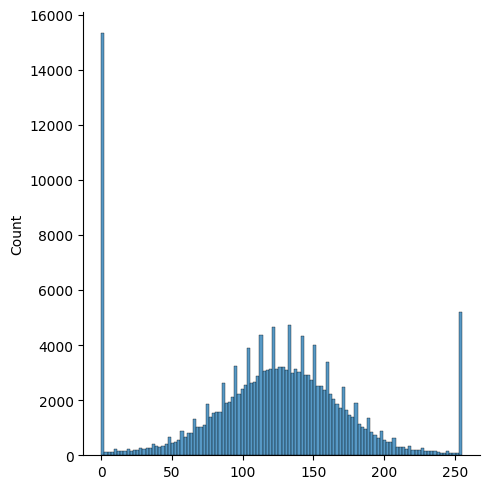

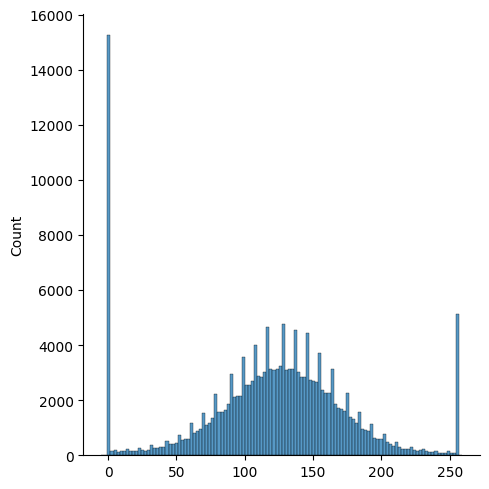

In [ ]:
An_float = model_qat_all.generate_An_QAT_PTQ(X_test)
S_An = model_qat_all.S_An
Zp_An = model_qat_all.Zp_An

An_quant_temp = np.round(An_float / S_An + Zp_An)
An_int8 = np.clip(An_quant_temp, 0, 255).astype(np.uint8)

sns.displot(An_int8.reshape(-1))
plt.show()
sns.displot(An_quant_temp.reshape(-1))

In [314]:
An_int8.reshape(-1).min(), An_int8.reshape(-1).max(), An_quant_temp.reshape(-1).min(), An_quant_temp.reshape(-1).max()

(0, 255, -5.0, 259.0)

In [315]:
np.savez(
    'bls_qat_test_data.npz', 
    input_An_features=An_int8, 
    y_true_float=y_test
)

print("Quantized An test data saved to: bls_qat_test_data.npz")

Quantized An test data saved to: bls_qat_test_data.npz


In [324]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tf2onnx.convert import from_keras

# --- Configuration (Set this to your feature count) ---
N_AN_COLS = 98 # Your A_n feature count


# --- PART 1: Define a Keras model with a FIXED Batch Size (1) ---

# 1. Define the input tensor with a FIXED BATCH SIZE of 1
input_layer = keras.Input(shape=(N_AN_COLS,), batch_size=1, dtype='float32', name='input_An')

# 2. Recreate the final Dense layer (Assuming no activation function here)
output_layer = keras.layers.Dense(
    units=1,
    activation='linear', # Use 'linear' if it's a regression layer
    use_bias=True,
    name='output_Y'
)(input_layer)

model_onnx_export = keras.Model(inputs=input_layer, outputs=output_layer)

# 3. Load the QAT W_n weights and bias
# --- YOU MUST REPLACE THESE WITH YOUR ACTUAL WEIGHTS FROM model_qat_all ---
# Wn_weights = model_qat_all.Wn 
# Wn_bias = model_qat_all.Wn_bias 

# model_onnx_export.get_layer('output_Y').set_weights([Wn_weights, Wn_bias])
# -------------------------------------------------------------------------


# --- PART 2: Export to ONNX with Fixed Input Signature ---

# Input signature must match the fixed batch size definition
input_signature = [
    tf.TensorSpec(shape=[1, N_AN_COLS], dtype=tf.float32, name='input_An')
]

onnx_model, _ = from_keras(
    model_onnx_export,
    input_signature=input_signature,
    opset=13,
    output_path="bls_qat_final_layer_fixed.onnx"
)

print("New ONNX model saved to: bls_qat_final_layer_fixed.onnx")


# --- PART 3: Create a single-sample NPZ file ---

# Assuming An_int8 and y_test are loaded from your test data
# An_int8 = ... (Your full noisy int8 A_n matrix)
# y_test = ...  (Your full float y_test labels)

# Use only the first sample of the NOISY int8 data, ensuring 2D shape (1, 98)
An_int8_sample = An_int8[0:1, :]
y_test_sample = y_test[0:1] 

np.savez(
    'bls_qat_test_data_single_sample.npz', 
    input_An_features=An_int8_sample, 
    y_true_float=y_test_sample
)

print("Single-sample NPZ file saved to: bls_qat_test_data_single_sample.npz")

New ONNX model saved to: bls_qat_final_layer_fixed.onnx
Single-sample NPZ file saved to: bls_qat_test_data_single_sample.npz


## STM32Cube.AI did not javab :(

## C implementation


In [327]:
model_chosen = BLS_reg_9(0.1, 1, 10, 8, 6, 3)
model_chosen.fit(X_train, y_train, QAT=True)

True

### model constants

In [ ]:
np.savez(
    'BLS_FINAL_CONSTANTS.npz', 
    
    # --- Weights ---
    # We save the float weights. We will quantize them in C.
    We=model_chosen.We,  # List of We arrays
    Wh=model_chosen.Wh,  # List of Wh arrays
    Wn=model_chosen.Wn,  # Final Wn array

    # --- Quantization Parameters (S and Zp) ---
    # These are all the S/Zp values from your "Pure Asymmetric" model
    S_X=model_chosen.S_X,       Zp_X=model_chosen.Zp_X,
    S_We=model_chosen.S_We,     Zp_We=model_chosen.Zp_We, 
    S_Zn=model_chosen.S_Zn,     Zp_Zn=model_chosen.Zp_Zn,
    S_Wh=model_chosen.S_Wh,     Zp_Wh=model_chosen.Zp_Wh, 
    S_Hn=model_chosen.S_Hn,     Zp_Hn=model_chosen.Zp_Hn,
    S_An=model_chosen.S_An,     Zp_An=model_chosen.Zp_An, # For the final An input
    S_Wn=model_chosen.S_Wn,     Zp_Wn=model_chosen.Zp_Wn, # For the final Wn

    # --- BLS-Specific Constants ---
    win_mean=model_chosen.win_mean,
    win_dist=model_chosen.win_dist,
    clip_min=model_chosen.clip_min,
    clip_max=model_chosen.clip_max,
    scaler_mean=model_chosen.scaler.mean_,
    scaler_std=model_chosen.scaler.scale_ # The 'scale_' attribute is the std deviation
)

print("All model constants saved to: BLS_FINAL_CONSTANTS.npz")

All model constants saved to: BLS_FINAL_CONSTANTS.npz


In [ ]:
# --- Run This Python Code ---
import numpy as np

# model_qat = ... (Load your final, best model object)

np.savez(
    'BLS_FINAL_CONSTANTS.npz', 
    
    # --- Weights ---
    # We save the float weights. We will quantize them in C.
    We=model_qat.We,  # List of We arrays
    Wh=model_qat.Wh,  # List of Wh arrays
    Wn=model_qat.Wn,  # Final Wn array

    # --- Quantization Parameters (S and Zp) ---
    # These are all the S/Zp values from your "Pure Asymmetric" model
    S_X=model_qat.S_X,       Zp_X=model_qat.Zp_X,
    S_We=model_qat.S_We,     Zp_We=model_qat.Zp_We, 
    S_Zn=model_qat.S_Zn,     Zp_Zn=model_qat.Zp_Zn,
    S_Wh=model_qat.S_Wh,     Zp_Wh=model_qat.Zp_Wh, 
    S_Hn=model_qat.S_Hn,     Zp_Hn=model_qat.Zp_Hn,
    S_An=model_qat.S_An,     Zp_An=model_qat.Zp_An, # For the final An input
    S_Wn=model_qat.S_Wn,     Zp_Wn=model_qat.Zp_Wn, # For the final Wn

    # --- BLS-Specific Constants ---
    win_mean=model_qat.win_mean,
    win_dist=model_qat.win_dist,
    clip_min=model_qat.clip_min,
    clip_max=model_qat.clip_max,
    scaler_mean=model_qat.scaler.mean_,
    scaler_std=model_qat.scaler.scale_ # The 'scale_' attribute is the std deviation
)

print("All model constants saved to: BLS_FINAL_CONSTANTS.npz")

[ 2.71874588e-01  3.63822250e+03  4.46712513e+03  9.23682908e+00
  3.24397585e+01  4.75612372e+01  1.22898835e+02  2.10671329e-01
  9.20433697e+01  2.70495746e+03  2.53007622e+01  3.33254900e+03
  6.66701705e+01 -1.07110493e-02  1.02480242e+02  9.23774099e+01] [1.43282844e-03 1.97195405e+01 2.45350864e+01 5.79093281e-02
 2.16486914e-01 1.90539628e-01 1.13024354e-02 2.91162935e-03
 6.12149391e-02 6.69434752e-01 1.38722557e-01 7.55675746e-01
 1.34598998e-02 1.03644501e+00 1.51184350e-02 1.52663570e-01]
offline RMSE on mode 0 with 260 samples: 0.2289514432544955
Online predict RMSE on 0th sample:	0.14665819483202824
Online predict RMSE on 1th sample:	0.11363607455874813
Online predict RMSE on 2th sample:	0.024635515680873965
Online predict RMSE on 3th sample:	0.10317938648880087
Online predict RMSE on 4th sample:	0.001616327724011768
Online predict RMSE on 5th sample:	0.01855343087981609
Online predict RMSE on 6th sample:	0.13182805525946506
Online predict RMSE on 7th sample:	0.0165407837

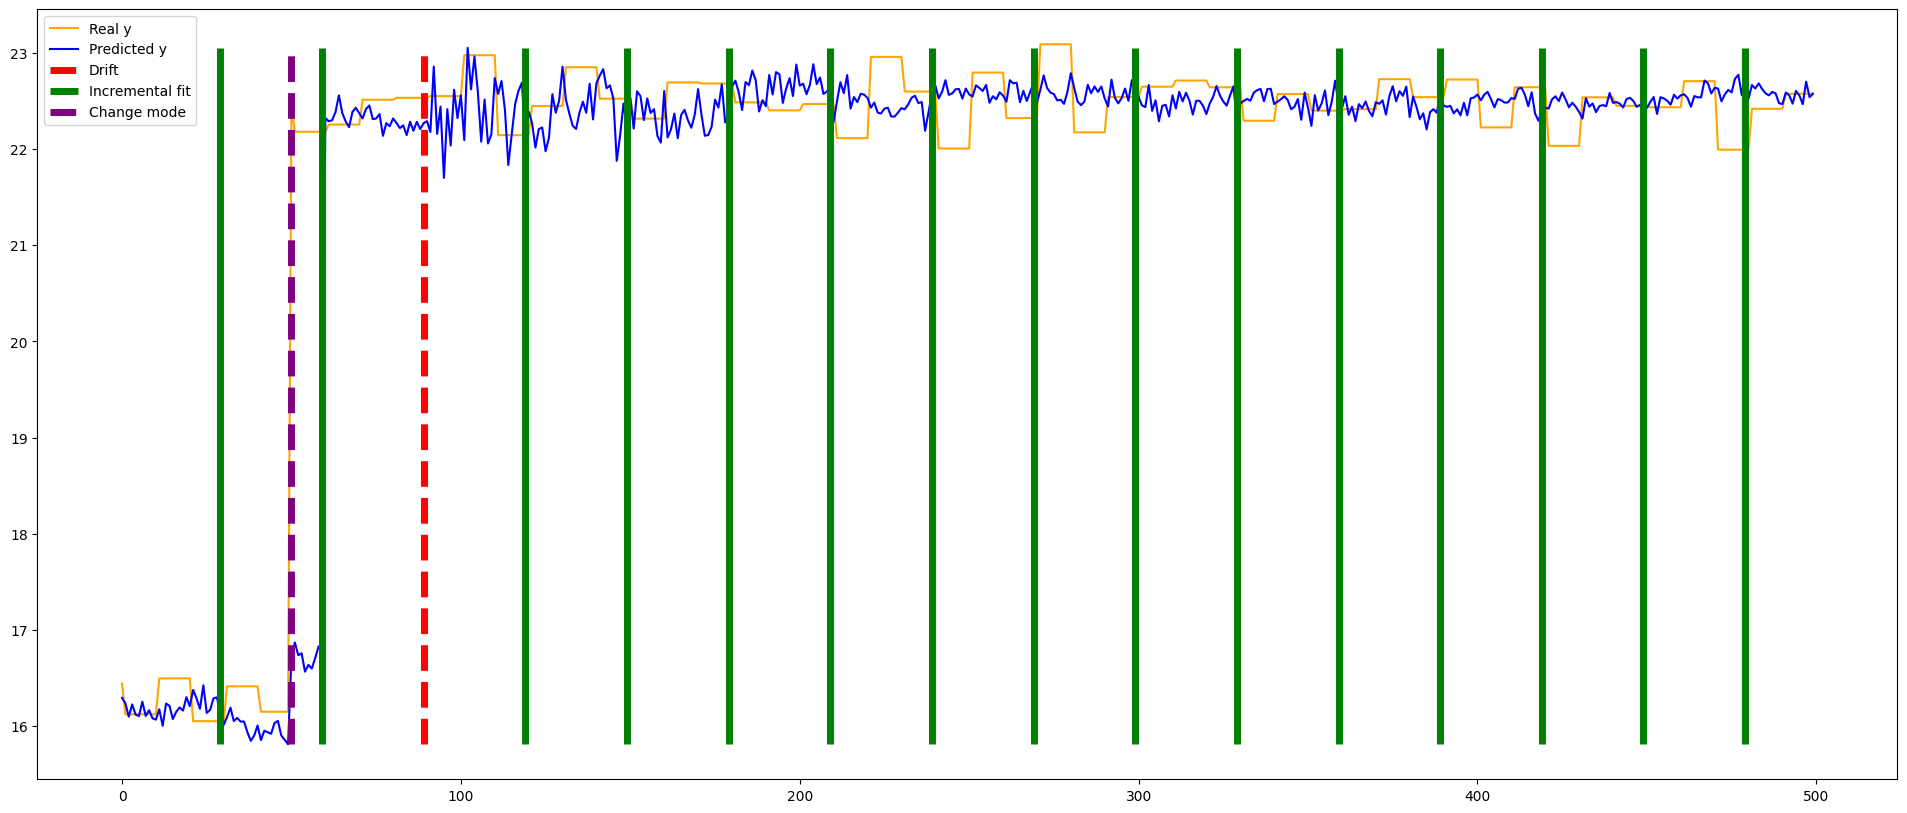

In [114]:
n_X_start = 260
buffer_size = 30
change_mode = 50
end_m0 = n_X_start + change_mode
end_m1 = 450
chosen_feature = 10
buffer = np.array([])
buffer_y = np.array([])
pred_y_list = []
drift_detect_list = []
incremental_detect_list = []
first_mode = 0
second_mode = 1

buffer_scaler = standard_scaler()

stream_X = np.vstack([data_X[first_mode][n_X_start:end_m0,:], data_X[second_mode][end_m0:end_m1+end_m0,:]])
stream_y = np.hstack([data_y[first_mode][n_X_start:end_m0], data_y[second_mode][end_m0:end_m1+end_m0]])

#-------offline phase------------
#buffer
old_buffer_X = data_X[first_mode][(n_X_start - buffer_size):n_X_start, :]
old_buffer_y = data_y[first_mode][(n_X_start - buffer_size):n_X_start]
#preprocessing
buffer_scaler.fit(old_buffer_X)
data_X_std = buffer_scaler.transform(data_X[first_mode][:n_X_start,:])
print(buffer_scaler.mean, buffer_scaler.std)
#define and fit
model_6 = BLS_regression(0.001, 1, 10, 8, 6, 3, buffer_size)
model_6.fit(data_X_std, data_y[first_mode][:n_X_start])
print(f"offline RMSE on mode {first_mode} with {n_X_start} samples: {model_6.fit_RMSE}")

#-------online phase-------------

for idx in range(len(stream_X)):
    x = stream_X[idx]
    y = stream_y[idx]

    x_std = buffer_scaler.transform(x)

    if idx == change_mode: print('\n---------------> new mode <-----------------\n')

    #predict new sample
    model_6.predict(x_std.reshape(1, data_X[first_mode].shape[1]), y.reshape(-1, 1))
    if len(model_6.pred_y.shape) == 1:
        pred_y_list.append(model_6.pred_y[0])
    else:
        pred_y_list.append(model_6.pred_y[0,0])
    # pred_y_list.append(model_6.pred_y)

    print(f'Online predict RMSE on {idx}th sample:\t{model_6.pred_RMSE}')

    #buffer
    if len(buffer) > 0:
        buffer = np.vstack([buffer, x])
        buffer_y = np.vstack([buffer_y, y])
    else:
        buffer = x
        buffer_y = y
    
    if len(buffer) == buffer_size:
        buffer = np.array(buffer)
        # is_drift = []
        # for chosen_feature in [1, 8, 10]: 
            # _, tempp = ks_2samp(old_buffer_X[:, chosen_feature], buffer[:, chosen_feature])
            # is_drift.append(tempp <= 0.05)
        chosen_feature = 8
        is_drift = model_6.ks_drift_detector3(old_buffer_X[:, chosen_feature], buffer[:, chosen_feature], .001)
        #drift detected
        if is_drift:
            #scaler redefine
            buffer_scaler.fit(buffer)
            #preprocess buffer
            std_buffer = buffer_scaler.transform(buffer)
            
            transfer = True
            if transfer:
                # fit transfer
                model_6.fit_transfer(std_buffer, buffer_y)
                print(f'\n--->Drift detected!\nOnline buffer fit RMSE: {model_6.trns_RMSE}\n')
                model_6.fit_incremental(buffer_std, buffer_y)
                print(f'\nOnline buffer fit_incremental RMSE: {model_6.inc_RMSE}\n')

            else:
                # fit new model
                model_6.fit(std_buffer, buffer_y)
                print(f'\n--->Drift detected!\nOnline buffer fit RMSE: {model_6.fit_RMSE}\n')
                # model_6.fit_incremental(buffer_std, buffer_y)
                # print(f'\nOnline buffer fit_incremental RMSE: {model_6.inc_RMSE}\n')
            
            drift_detect_list.append(idx)
        else: #or elif RMSE > threshold
            #preprocess buffer
            buffer_std = buffer_scaler.transform(buffer)
            model_6.fit_incremental(buffer_std, buffer_y)
            print(f'\nOnline buffer fit_incremental RMSE: {model_6.inc_RMSE}\n')
            # if rmse > 0.25:
            #     model_6.fit_incremental(buffer, buffer_y)
            incremental_detect_list.append(idx)

        old_buffer_X = buffer
        old_buffer_y = buffer_y
        buffer = np.array([])
        buffer_y = np.array([])
    
ymin = min(pred_y_list)
ymax = max(pred_y_list)
xxx = np.arange(len(stream_X))
plt.figure(figsize=(24, 10))
plt.plot(xxx, stream_y, color = 'orange', label = 'Real y')
plt.plot(xxx, pred_y_list, color = 'b', label = 'Predicted y')
plt.vlines(x = drift_detect_list, ymin=ymin, ymax=ymax, color = 'red', label = 'Drift', linewidth = 5, linestyle = 'dashed')
plt.vlines(x = incremental_detect_list, ymin=ymin, ymax=ymax, color = 'green', label = 'Incremental fit', linewidth = 5)
plt.vlines(x = change_mode, ymin=ymin, ymax=ymax, color = 'purple', label = 'Change mode', linewidth = 5, linestyle = 'dashed')
plt.legend()       

